<a href="https://colab.research.google.com/github/sjfjawe/Airline-Customer-Satisfaction-Prediction/blob/main/notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Which passengers are likely to respond in neutral or disatisfaction?

Data source: https://huggingface.co/datasets/drukeroni/airline-satisfaction-analysis

**Original data were already split into 'train' and 'test'....**

##1. Combine the train + test; Data Prep

In [23]:
import pandas as pd

splits = {'train': 'train.csv', 'test': 'test.csv'}

df_train = pd.read_csv("hf://datasets/drukeroni/airline-satisfaction-analysis/" + splits["train"])
df_test  = pd.read_csv("hf://datasets/drukeroni/airline-satisfaction-analysis/" + splits["test"])

print(df_train.shape)
print(df_test.shape)
df_train.head()

(103904, 25)
(25976, 25)


,Unnamed: 0,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,...,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,0,70172,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,...,5,4,3,4,4,5,5,25,18.0,neutral or dissatisfied
1,1,5047,Male,disloyal Customer,25,Business travel,Business,235,3,2,...,1,1,5,3,1,4,1,1,6.0,neutral or dissatisfied
2,2,110028,Female,Loyal Customer,26,Business travel,Business,1142,2,2,...,5,4,3,4,4,4,5,0,0.0,satisfied
3,3,24026,Female,Loyal Customer,25,Business travel,Business,562,2,5,...,2,2,5,3,1,4,2,11,9.0,neutral or dissatisfied
4,4,119299,Male,Loyal Customer,61,Business travel,Business,214,3,3,...,3,3,4,4,3,3,3,0,0.0,satisfied


In [24]:
cols_to_drop = ['Unnamed: 0', 'id']

df_train.drop(columns=cols_to_drop, inplace=True, errors='ignore')
df_test.drop(columns=cols_to_drop, inplace=True, errors='ignore')

df_whole = pd.concat([df_train, df_test], ignore_index=True)
print(df_whole.shape)   # should show 103k + 26k
df_whole.head()

(129880, 23)


,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,...,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,3,1,...,5,4,3,4,4,5,5,25,18.0,neutral or dissatisfied
1,Male,disloyal Customer,25,Business travel,Business,235,3,2,3,3,...,1,1,5,3,1,4,1,1,6.0,neutral or dissatisfied
2,Female,Loyal Customer,26,Business travel,Business,1142,2,2,2,2,...,5,4,3,4,4,4,5,0,0.0,satisfied
3,Female,Loyal Customer,25,Business travel,Business,562,2,5,5,5,...,2,2,5,3,1,4,2,11,9.0,neutral or dissatisfied
4,Male,Loyal Customer,61,Business travel,Business,214,3,3,3,3,...,3,3,4,4,3,3,3,0,0.0,satisfied


In [25]:
df_whole.columns = df_whole.columns.str.replace(' ', '_')
df_test.columns = df_test.columns.str.replace(' ', '_')
df_train.columns = df_train.columns.str.replace(' ', '_')
print(df_whole.dtypes)


Gender                                object
Customer_Type                         object
Age                                    int64
Type_of_Travel                        object
Class                                 object
Flight_Distance                        int64
Inflight_wifi_service                  int64
Departure/Arrival_time_convenient      int64
Ease_of_Online_booking                 int64
Gate_location                          int64
Food_and_drink                         int64
Online_boarding                        int64
Seat_comfort                           int64
Inflight_entertainment                 int64
On-board_service                       int64
Leg_room_service                       int64
Baggage_handling                       int64
Checkin_service                        int64
Inflight_service                       int64
Cleanliness                            int64
Departure_Delay_in_Minutes             int64
Arrival_Delay_in_Minutes             float64
satisfacti

##2. Explore data structure

In [26]:
for col in df_whole.columns:
    print(col)
    print(df_whole[col].unique()[:5])
    print(df_whole[col].nunique())
    print("-----------------")

Gender
['Male' 'Female']
2
-----------------
Customer_Type
['Loyal Customer' 'disloyal Customer']
2
-----------------
Age
[13 25 26 61 47]
75
-----------------
Type_of_Travel
['Personal Travel' 'Business travel']
2
-----------------
Class
['Eco Plus' 'Business' 'Eco']
3
-----------------
Flight_Distance
[ 460  235 1142  562  214]
3821
-----------------
Inflight_wifi_service
[3 2 4 1 5]
6
-----------------
Departure/Arrival_time_convenient
[4 2 5 3 1]
6
-----------------
Ease_of_Online_booking
[3 2 5 4 1]
6
-----------------
Gate_location
[1 3 2 5 4]
6
-----------------
Food_and_drink
[5 1 2 4 3]
6
-----------------
Online_boarding
[3 5 2 1 4]
6
-----------------
Seat_comfort
[5 1 2 3 4]
6
-----------------
Inflight_entertainment
[5 1 2 3 4]
6
-----------------
On-board_service
[4 1 2 3 5]
6
-----------------
Leg_room_service
[3 5 4 2 1]
6
-----------------
Baggage_handling
[4 3 5 1 2]
5
-----------------
Checkin_service
[4 1 3 5 2]
6
-----------------
Inflight_service
[5 4 3 1 2]
6
---

##2.1 explore numerical_features


In [27]:
numerical_features = df_whole.select_dtypes(include=['int64', 'float64']).columns.to_list()
print(numerical_features)

['Age', 'Flight_Distance', 'Inflight_wifi_service', 'Departure/Arrival_time_convenient', 'Ease_of_Online_booking', 'Gate_location', 'Food_and_drink', 'Online_boarding', 'Seat_comfort', 'Inflight_entertainment', 'On-board_service', 'Leg_room_service', 'Baggage_handling', 'Checkin_service', 'Inflight_service', 'Cleanliness', 'Departure_Delay_in_Minutes', 'Arrival_Delay_in_Minutes']


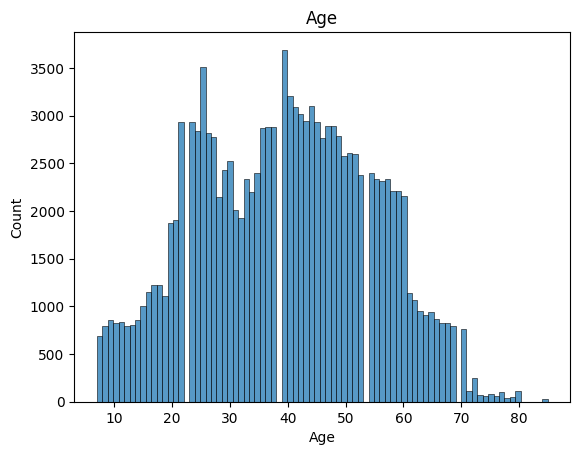

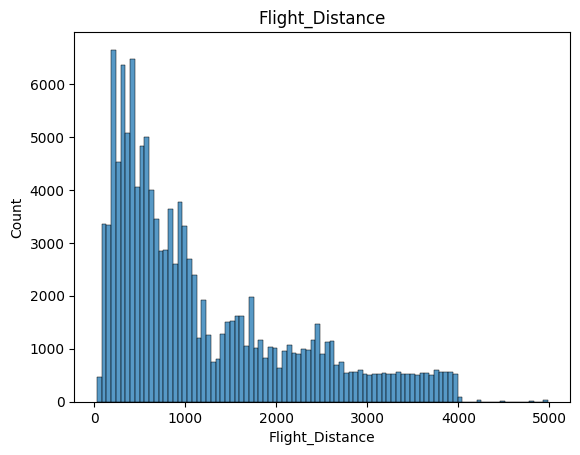

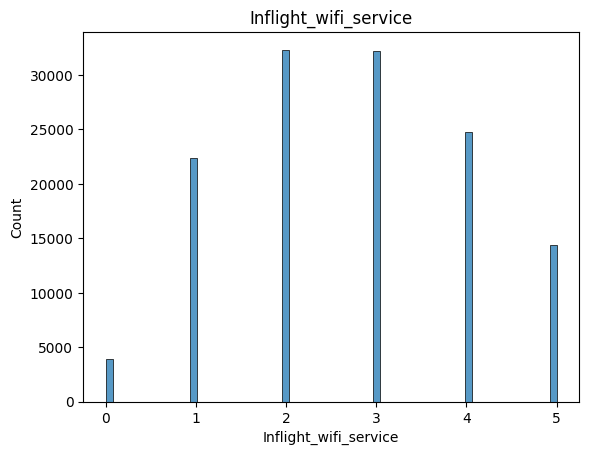

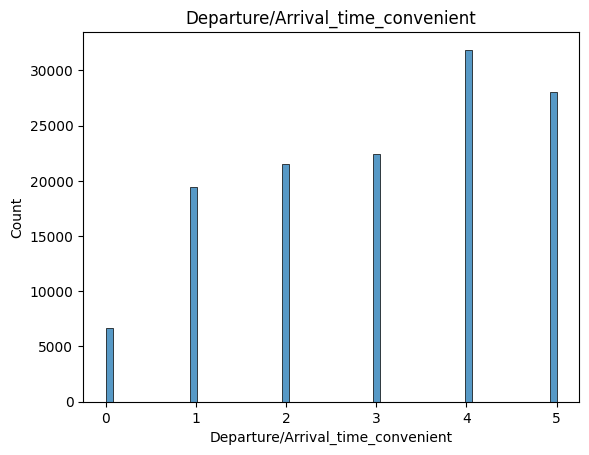

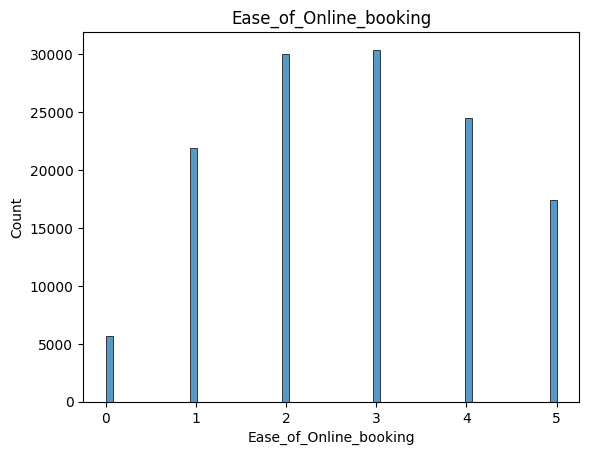

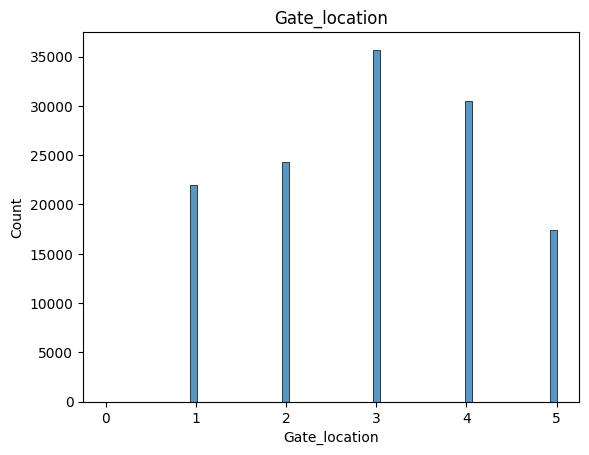

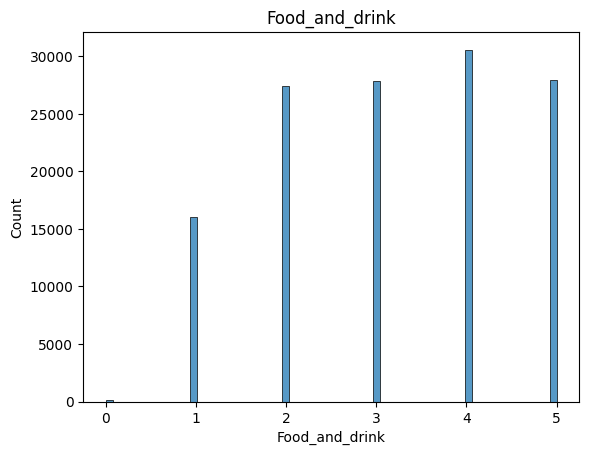

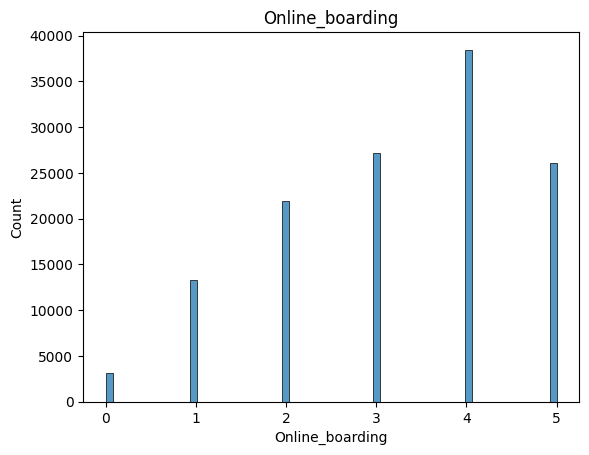

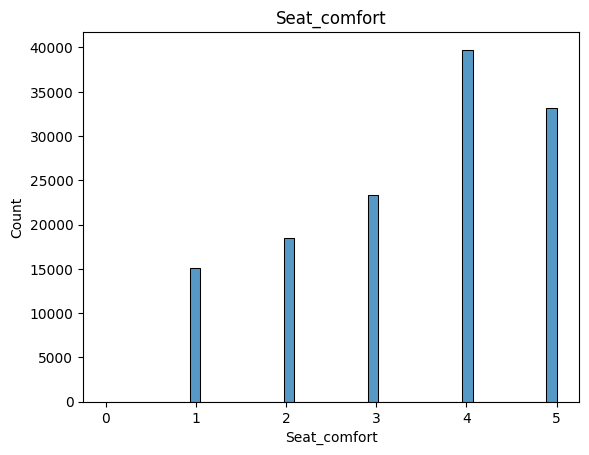

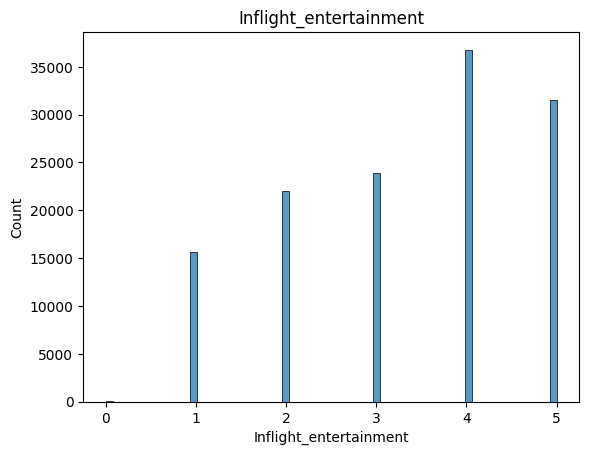

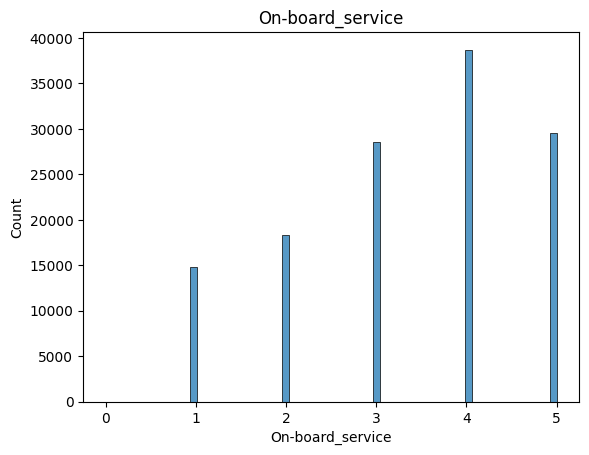

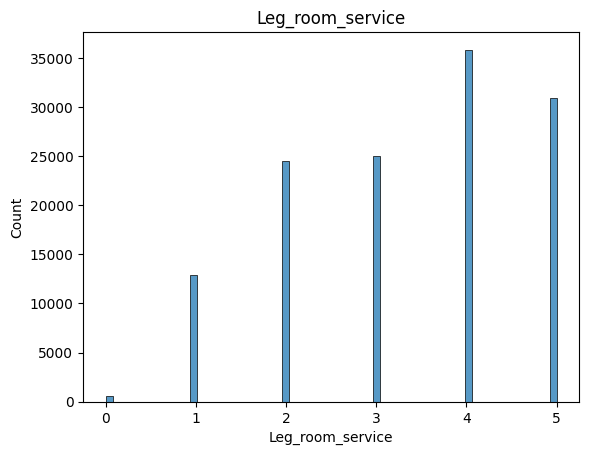

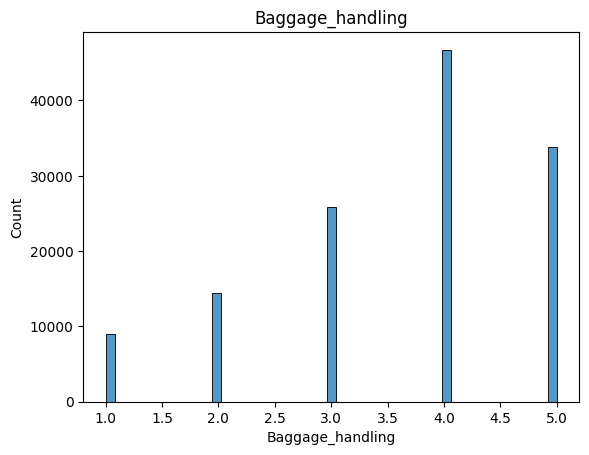

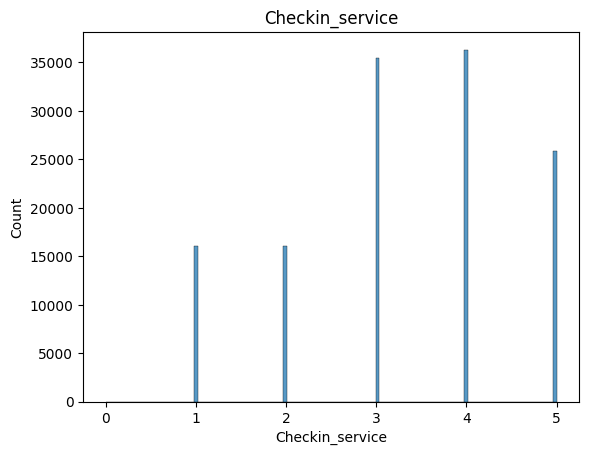

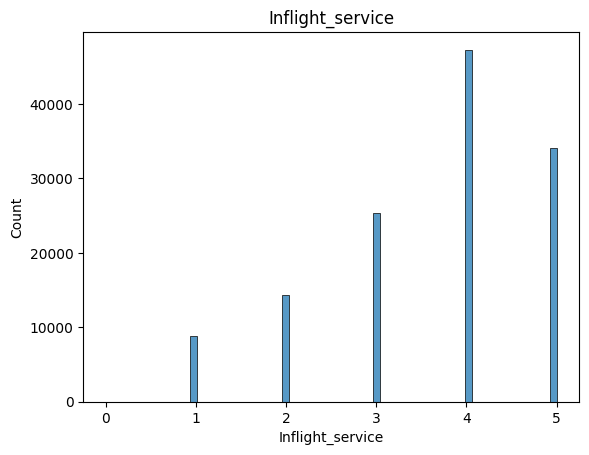

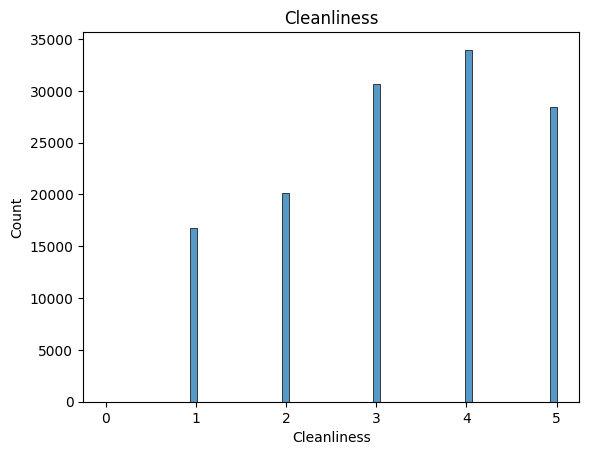

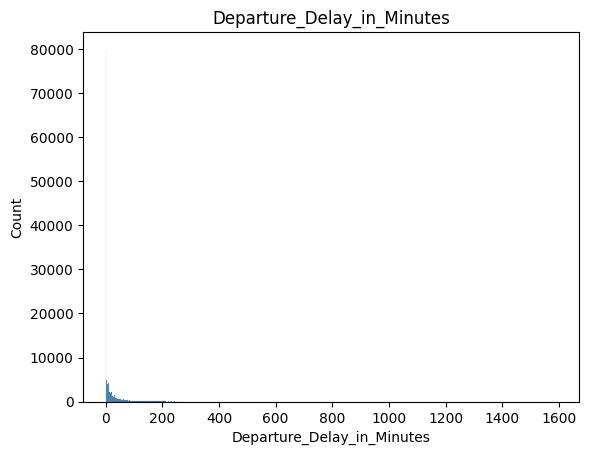

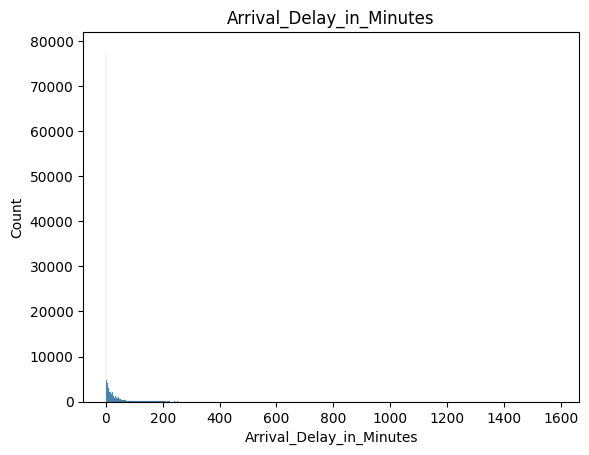

<Axes: ylabel='Count'>

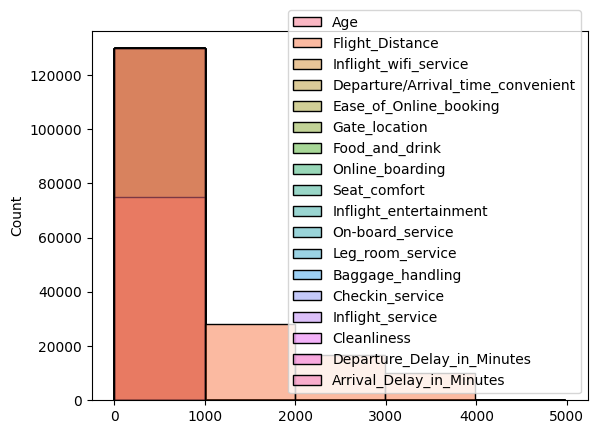

In [28]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

for i in numerical_features:
    sns.histplot(df_whole[i])
    plt.title(i)
    plt.show()

sns.histplot(df_whole, bins=5)

In [29]:
df_whole[numerical_features].describe()

,Age,Flight_Distance,Inflight_wifi_service,Departure/Arrival_time_convenient,Ease_of_Online_booking,Gate_location,Food_and_drink,Online_boarding,Seat_comfort,Inflight_entertainment,On-board_service,Leg_room_service,Baggage_handling,Checkin_service,Inflight_service,Cleanliness,Departure_Delay_in_Minutes,Arrival_Delay_in_Minutes
count,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129487.000000
mean,39.427957,1190.316392,2.728696,3.057599,2.756876,2.976925,3.204774,3.252633,3.441361,3.358077,3.383023,3.350878,3.632114,3.306267,3.642193,3.286326,14.713713,15.091129
std,15.119360,997.452477,1.329340,1.526741,1.401740,1.278520,1.329933,1.350719,1.319289,1.334049,1.287099,1.316252,1.180025,1.266185,1.176669,1.313682,38.071126,38.465650
min,7.000000,31.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,27.000000,414.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,3.000000,3.000000,3.000000,2.000000,0.000000,0.000000
50%,40.000000,844.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,4.000000,4.000000,4.000000,4.000000,4.000000,3.000000,4.000000,3.000000,0.000000,0.000000
75%,51.000000,1744.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,5.000000,4.000000,4.000000,4.000000,5.000000,4.000000,5.000000,4.000000,12.000000,13.000000
max,85.000000,4983.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,1592.000000,1584.000000


<Axes: xlabel='Arrival_Delay_in_Minutes', ylabel='Count'>

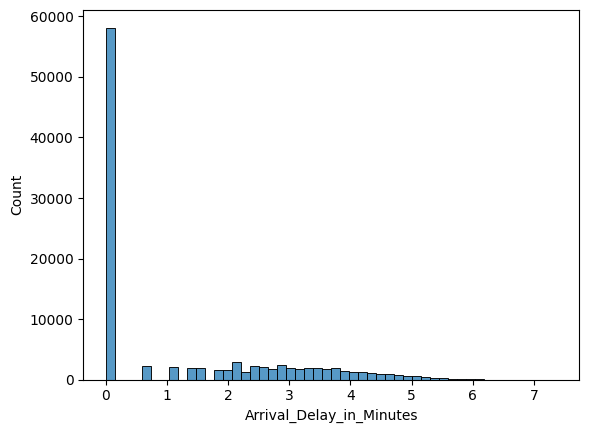

In [30]:
#Removing the long tail with a logarithm
np.log1p([0, 1, 10, 1000, 100000])

df_whole['Departure_Delay_in_Minutes'] = np.log1p(df_whole['Departure_Delay_in_Minutes'])
df_train['Departure_Delay_in_Minutes'] = np.log1p(df_train['Departure_Delay_in_Minutes'])
df_test['Departure_Delay_in_Minutes'] = np.log1p(df_test['Departure_Delay_in_Minutes'])

df_whole['Arrival_Delay_in_Minutes'] = np.log1p(df_whole['Arrival_Delay_in_Minutes'])
df_train['Arrival_Delay_in_Minutes'] = np.log1p(df_train['Arrival_Delay_in_Minutes'])
df_test['Arrival_Delay_in_Minutes'] = np.log1p(df_test['Arrival_Delay_in_Minutes'])

sns.histplot(df_train.Arrival_Delay_in_Minutes, bins=50)

Text(0.5, 1.0, 'Arrival_Delay impact on customer satisfaction')

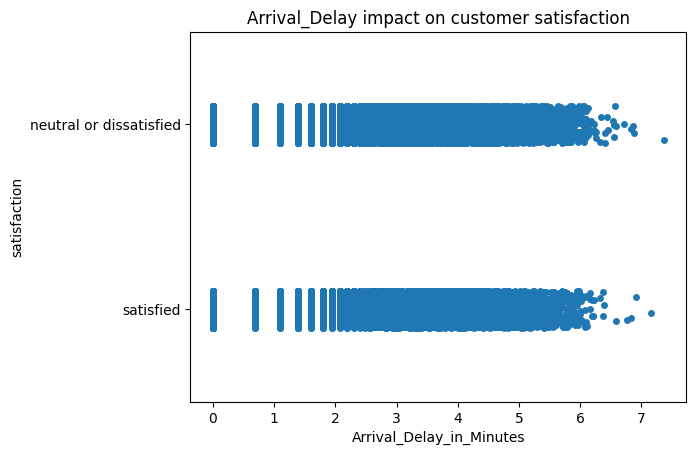

In [31]:
sns.stripplot(x=df_train['Arrival_Delay_in_Minutes'], y=df_train['satisfaction'])
plt.title('Arrival_Delay impact on customer satisfaction')

Text(0.5, 1.0, 'Departure_Delay impact on customer satisfaction')

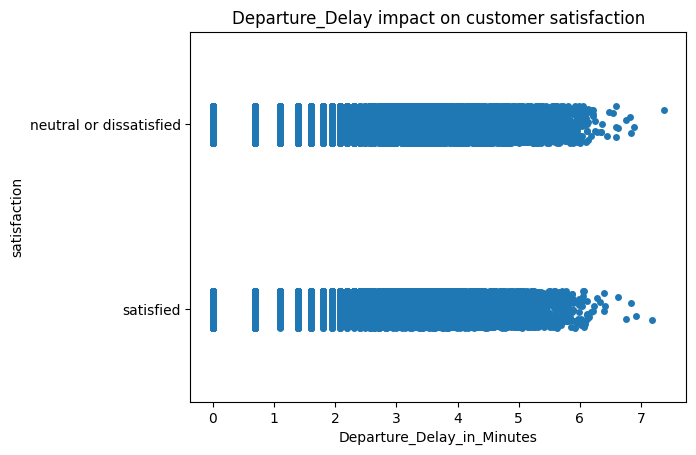

In [32]:
sns.stripplot(x=df_train['Departure_Delay_in_Minutes'], y=df_train['satisfaction'])
plt.title('Departure_Delay impact on customer satisfaction')

In [33]:
no_Departure_delay = np.sum(df_whole['Departure_Delay_in_Minutes'] == 0)
has_Departure_delay = np.sum(df_whole['Departure_Delay_in_Minutes'] > 0)

print(f"No Departure delay:  {no_Departure_delay}")
print(f"Has Departure delay: {has_Departure_delay}")
print("-----------------")
no_Arrival_delay = np.sum(df_whole['Arrival_Delay_in_Minutes'] == 0)
has_Arrival_delay = np.sum(df_whole['Arrival_Delay_in_Minutes'] > 0)

print(f"No Arrival delay:  {no_Arrival_delay}")
print(f"Has Arrival delay: {has_Arrival_delay}")
print("-----------------")
print(f"Total:     {len(df_whole)}")

No Departure delay:  73356
Has Departure delay: 56524
-----------------
No Arrival delay:  72753
Has Arrival delay: 56734
-----------------
Total:     129880


In [34]:
# feature engineer: Create has_delay column because: 1) delay v.s. no_delay for both Arrival and Departure are about equal split
# 2) these 2 dimensions are correlate -- if there's delay in depature it's very likely to inroduce delay in arrival 3)lots of dp is 'no delay'
df_train['has_delay'] = ((df_train['Departure_Delay_in_Minutes'] > 0) | (df_train['Arrival_Delay_in_Minutes'] > 0)).astype(int)
df_test['has_delay']  = ((df_test['Departure_Delay_in_Minutes'] > 0)  | (df_test['Arrival_Delay_in_Minutes'] > 0)).astype(int)

# Verify
print(df_train['has_delay'].value_counts())
print(df_test['has_delay'].value_counts())


has_delay
1    56329
0    47575
Name: count, dtype: int64
has_delay
1    14053
0    11923
Name: count, dtype: int64


In [35]:
df_train.head()

,Gender,Customer_Type,Age,Type_of_Travel,Class,Flight_Distance,Inflight_wifi_service,Departure/Arrival_time_convenient,Ease_of_Online_booking,Gate_location,...,On-board_service,Leg_room_service,Baggage_handling,Checkin_service,Inflight_service,Cleanliness,Departure_Delay_in_Minutes,Arrival_Delay_in_Minutes,satisfaction,has_delay
0,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,3,1,...,4,3,4,4,5,5,3.258097,2.944439,neutral or dissatisfied,1
1,Male,disloyal Customer,25,Business travel,Business,235,3,2,3,3,...,1,5,3,1,4,1,0.693147,1.945910,neutral or dissatisfied,1
2,Female,Loyal Customer,26,Business travel,Business,1142,2,2,2,2,...,4,3,4,4,4,5,0.000000,0.000000,satisfied,0
3,Female,Loyal Customer,25,Business travel,Business,562,2,5,5,5,...,2,5,3,1,4,2,2.484907,2.302585,neutral or dissatisfied,1
4,Male,Loyal Customer,61,Business travel,Business,214,3,3,3,3,...,3,4,4,3,3,3,0.000000,0.000000,satisfied,0


##2.2 explore categorical_features


In [36]:
categorical_features = df_whole.select_dtypes(include='object').columns.tolist()
print(df_whole[categorical_features].isna().sum())

Gender            0
Customer_Type     0
Type_of_Travel    0
Class             0
satisfaction      0
dtype: int64


Column: Gender, Unique values: 2


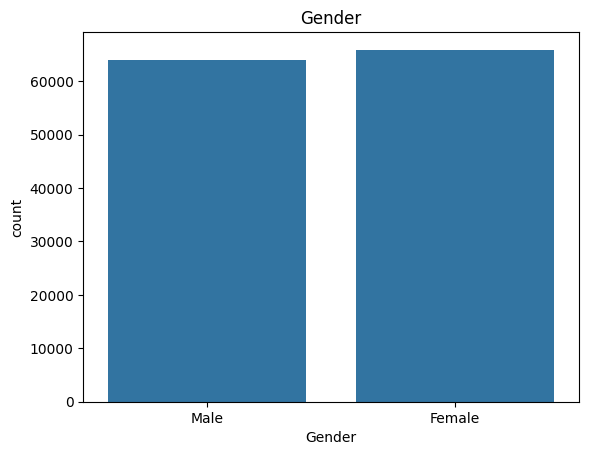

Column: Customer_Type, Unique values: 2


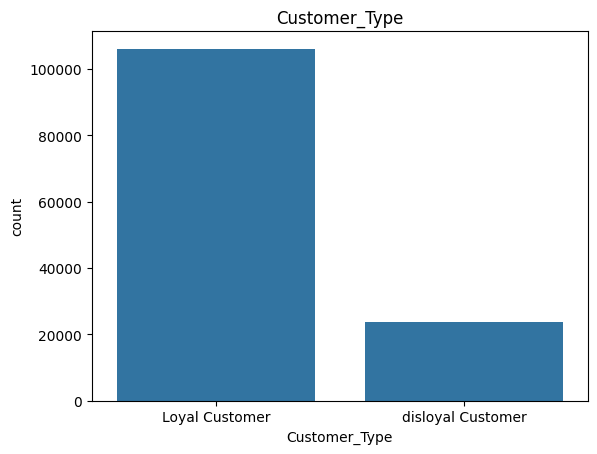

Column: Type_of_Travel, Unique values: 2


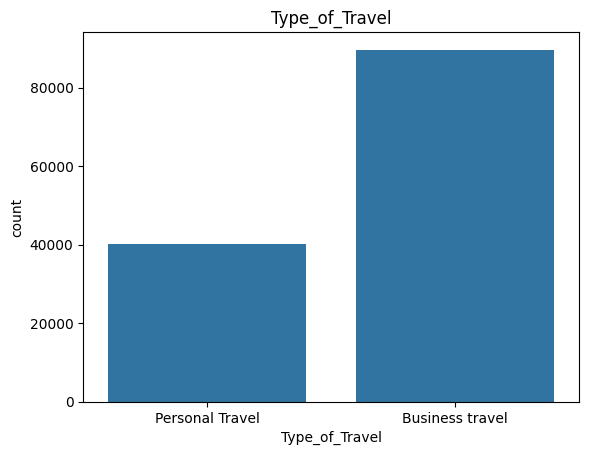

Column: Class, Unique values: 3


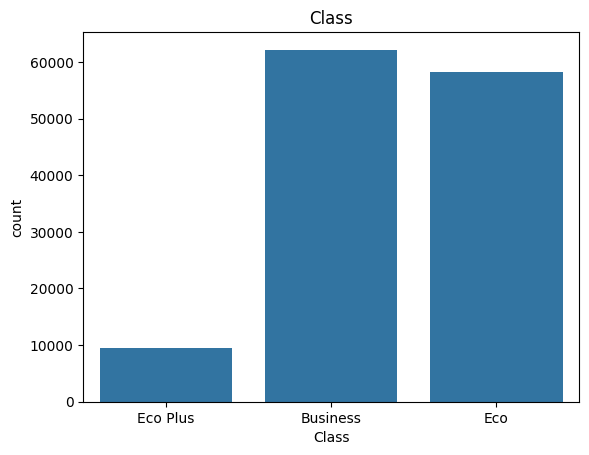

Column: satisfaction, Unique values: 2


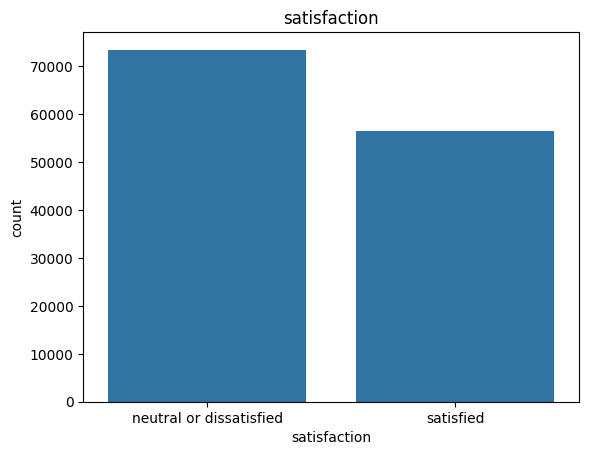

In [37]:
for c in categorical_features:
    print(f'Column: {c}, Unique values: {df_whole[c].nunique()}')
    sns.countplot(x=c, data=df_whole)
    plt.title(c)
    plt.show()

##3. validation framework
#### df_whole is df_train + df_test => used to explora data features
#### df_train will then split into val + train => use to train & validate
#### df_full_train is a backup copy of the original 'train' dataseet df_train


In [16]:
from sklearn.model_selection import train_test_split

df_full_train = df_train.copy()   # keep a backup of the original 'train' dataseet

df_train, df_val = train_test_split(df_full_train, test_size=0.2, random_state=42)
total = len(df_train) + len(df_val) + len(df_test)
print(f"Train size: {len(df_train)}; {len(df_train)/total*100:.2f}%")
print(f"Val size:   {len(df_val)}; {len(df_val)/total*100:.2f}%")
print(f"Test size:  {len(df_test)}; {len(df_test)/total*100:.2f}%")
print("-----------------")
df_train.head()


Train size: 83123; 64.00%
Val size:   20781; 16.00%
Test size:  25976; 20.00%
-----------------


,Gender,Customer_Type,Age,Type_of_Travel,Class,Flight_Distance,Inflight_wifi_service,Departure/Arrival_time_convenient,Ease_of_Online_booking,Gate_location,...,On-board_service,Leg_room_service,Baggage_handling,Checkin_service,Inflight_service,Cleanliness,Departure_Delay_in_Minutes,Arrival_Delay_in_Minutes,satisfaction,has_delay
20921,Female,Loyal Customer,59,Personal Travel,Eco,1046,4,5,4,1,...,2,4,3,5,2,4,2.564949,1.386294,neutral or dissatisfied,1
36897,Female,disloyal Customer,40,Business travel,Business,752,4,4,4,2,...,4,2,4,3,5,1,2.995732,3.401197,neutral or dissatisfied,1
8468,Male,Loyal Customer,65,Personal Travel,Eco,383,2,3,2,1,...,5,4,5,5,5,1,0.000000,0.000000,neutral or dissatisfied,0
53490,Female,Loyal Customer,70,Personal Travel,Eco,2239,3,5,3,4,...,5,3,5,3,5,5,0.000000,0.000000,neutral or dissatisfied,0
78687,Female,disloyal Customer,25,Business travel,Eco,1358,2,2,2,3,...,1,2,3,5,2,1,1.386294,2.772589,neutral or dissatisfied,1


In [17]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = (df_train.satisfaction == 'satisfied').astype('int').values
y_val = (df_val.satisfaction == 'satisfied').astype('int').values
y_test = (df_test.satisfaction == 'satisfied').astype('int').values

del df_train['satisfaction']
del df_val['satisfaction']
del df_test['satisfaction']
df_train.head()

,Gender,Customer_Type,Age,Type_of_Travel,Class,Flight_Distance,Inflight_wifi_service,Departure/Arrival_time_convenient,Ease_of_Online_booking,Gate_location,...,Inflight_entertainment,On-board_service,Leg_room_service,Baggage_handling,Checkin_service,Inflight_service,Cleanliness,Departure_Delay_in_Minutes,Arrival_Delay_in_Minutes,has_delay
0,Female,Loyal Customer,59,Personal Travel,Eco,1046,4,5,4,1,...,2,2,4,3,5,2,4,2.564949,1.386294,1
1,Female,disloyal Customer,40,Business travel,Business,752,4,4,4,2,...,1,4,2,4,3,5,1,2.995732,3.401197,1
2,Male,Loyal Customer,65,Personal Travel,Eco,383,2,3,2,1,...,1,5,4,5,5,5,1,0.000000,0.000000,0
3,Female,Loyal Customer,70,Personal Travel,Eco,2239,3,5,3,4,...,5,5,3,5,3,5,5,0.000000,0.000000,0
4,Female,disloyal Customer,25,Business travel,Eco,1358,2,2,2,3,...,1,1,2,3,5,2,1,1.386294,2.772589,1


In [38]:
df_val.head()

,Gender,Customer_Type,Age,Type_of_Travel,Class,Flight_Distance,Inflight_wifi_service,Departure/Arrival_time_convenient,Ease_of_Online_booking,Gate_location,...,Inflight_entertainment,On-board_service,Leg_room_service,Baggage_handling,Checkin_service,Inflight_service,Cleanliness,Departure_Delay_in_Minutes,Arrival_Delay_in_Minutes,has_delay
0,Female,Loyal Customer,26,Personal Travel,Eco,861,2,4,2,5,...,5,5,4,4,3,5,5,0.000000,0.000000,0
1,Male,Loyal Customer,22,Business travel,Business,393,3,5,5,5,...,3,1,1,3,2,3,3,0.000000,2.833213,1
2,Female,Loyal Customer,59,Personal Travel,Eco,196,1,3,1,3,...,4,4,1,4,3,4,4,3.637586,3.555348,1
3,Female,Loyal Customer,32,Personal Travel,Eco,1020,2,3,2,4,...,4,3,2,4,1,4,4,3.332205,1.609438,1
4,Male,disloyal Customer,35,Business travel,Business,1117,2,2,2,1,...,2,2,2,3,2,2,2,0.000000,0.000000,0


##4. correlations & mutual info

In [40]:
df_whole.satisfaction = (df_whole.satisfaction == 'satisfied').astype('int')
df_full_train.satisfaction = (df_full_train.satisfaction == 'satisfied').astype('int')

df_whole.head()

,Gender,Customer_Type,Age,Type_of_Travel,Class,Flight_Distance,Inflight_wifi_service,Departure/Arrival_time_convenient,Ease_of_Online_booking,Gate_location,...,Inflight_entertainment,On-board_service,Leg_room_service,Baggage_handling,Checkin_service,Inflight_service,Cleanliness,Departure_Delay_in_Minutes,Arrival_Delay_in_Minutes,satisfaction
0,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,3,1,...,5,4,3,4,4,5,5,3.258097,2.944439,0
1,Male,disloyal Customer,25,Business travel,Business,235,3,2,3,3,...,1,1,5,3,1,4,1,0.693147,1.945910,0
2,Female,Loyal Customer,26,Business travel,Business,1142,2,2,2,2,...,5,4,3,4,4,4,5,0.000000,0.000000,1
3,Female,Loyal Customer,25,Business travel,Business,562,2,5,5,5,...,2,2,5,3,1,4,2,2.484907,2.302585,0
4,Male,Loyal Customer,61,Business travel,Business,214,3,3,3,3,...,3,3,4,4,3,3,3,0.000000,0.000000,1


In [41]:
df_whole[numerical_features + ['satisfaction']].corr()

,Age,Flight_Distance,Inflight_wifi_service,Departure/Arrival_time_convenient,Ease_of_Online_booking,Gate_location,Food_and_drink,Online_boarding,Seat_comfort,Inflight_entertainment,On-board_service,Leg_room_service,Baggage_handling,Checkin_service,Inflight_service,Cleanliness,Departure_Delay_in_Minutes,Arrival_Delay_in_Minutes,satisfaction
Age,1.000000,0.099459,0.016116,0.036960,0.022565,-0.000398,0.023194,0.207572,0.159136,0.074947,0.057078,0.039119,-0.047991,0.033475,-0.051347,0.052565,-0.008897,-0.011754,0.134091
Flight_Distance,0.099459,1.000000,0.006701,-0.018914,0.065165,0.005520,0.057066,0.214825,0.157662,0.130507,0.111194,0.134533,0.064855,0.073608,0.059316,0.095648,0.007313,-0.007446,0.298085
Inflight_wifi_service,0.016116,0.006701,1.000000,0.344915,0.714807,0.338573,0.132214,0.457445,0.121513,0.207802,0.119928,0.160317,0.120376,0.043762,0.110029,0.131300,-0.026683,-0.033729,0.283460
Departure/Arrival_time_convenient,0.036960,-0.018914,0.344915,1.000000,0.437620,0.447510,0.000687,0.072287,0.008666,-0.008380,0.067297,0.010617,0.070833,0.091132,0.072195,0.009862,-0.001139,-0.002930,-0.054270
Ease_of_Online_booking,0.022565,0.065165,0.714807,0.437620,1.000000,0.460041,0.030514,0.404866,0.028561,0.046564,0.039064,0.109450,0.039148,0.008819,0.035373,0.015125,-0.007639,-0.011064,0.168877
Gate_location,-0.000398,0.005520,0.338573,0.447510,0.460041,1.000000,-0.002872,0.002756,0.002788,0.002741,-0.029019,-0.005181,0.000972,-0.039353,0.000310,-0.005918,0.006941,0.007612,-0.002793
Food_and_drink,0.023194,0.057066,0.132214,0.000687,0.030514,-0.002872,1.000000,0.233500,0.575846,0.623461,0.057404,0.033173,0.035321,0.085198,0.035210,0.658054,-0.025041,-0.034072,0.211340
Online_boarding,0.207572,0.214825,0.457445,0.072287,0.404866,0.002756,0.233500,1.000000,0.419253,0.283922,0.154242,0.123225,0.083541,0.204238,0.074058,0.329377,-0.029415,-0.044032,0.501749
Seat_comfort,0.159136,0.157662,0.121513,0.008666,0.028561,0.002788,0.575846,0.419253,1.000000,0.611837,0.130545,0.104272,0.074620,0.189979,0.068842,0.679613,-0.024226,-0.037469,0.348829
Inflight_entertainment,0.074947,0.130507,0.207802,-0.008380,0.046564,0.002741,0.623461,0.283922,0.611837,1.000000,0.418574,0.300397,0.379123,0.119554,0.406094,0.692511,-0.030157,-0.044261,0.398234


In [46]:
from IPython.display import display

satisfaction_mean = df_whole['satisfaction'].mean()

for cf in categorical_features:
  print (cf)
  df_group = df_whole.groupby(cf).satisfaction.agg(['mean', 'count'])
  df_group['compared to average satisfaction (diff)']=df_group['mean'] - satisfaction_mean
  df_group['how likely to satisfy (risk)']=df_group['mean'] / satisfaction_mean
  display(df_group)
  print('----------------')

Gender


,mean,count,compared to average satisfaction (diff),how likely to satisfy (risk)
Gender,,,,
Female,0.428975,65899,-0.005488,0.987368
Male,0.440115,63981,0.005652,1.013010


----------------
Customer_Type


,mean,count,compared to average satisfaction (diff),how likely to satisfy (risk)
Customer_Type,,,,
Loyal Customer,0.478115,106100,0.043652,1.100474
disloyal Customer,0.239697,23780,-0.194765,0.551710


----------------
Type_of_Travel


,mean,count,compared to average satisfaction (diff),how likely to satisfy (risk)
Type_of_Travel,,,,
Business travel,0.583724,89693,0.149262,1.343555
Personal Travel,0.101326,40187,-0.333136,0.233222


----------------
Class


,mean,count,compared to average satisfaction (diff),how likely to satisfy (risk)
Class,,,,
Business,0.694434,62160,0.259971,1.598374
Eco,0.187673,58309,-0.246790,0.431965
Eco Plus,0.246414,9411,-0.188049,0.567169


----------------
satisfaction


,mean,count,compared to average satisfaction (diff),how likely to satisfy (risk)
satisfaction,,,,
0,0.0,73452,-0.434463,0.000000
1,1.0,56428,0.565537,2.301694


----------------


In [45]:
from sklearn.metrics import mutual_info_score

def mutual_info_satisfaction(series):
    return mutual_info_score (series, df_whole.satisfaction)
mi = df_whole[categorical_features].apply(mutual_info_satisfaction)
mi.sort_values(ascending=False).to_frame(name='Mutual Info of the categorical features')

,Mutual Info of the categorical features
satisfaction,0.684532
Class,0.132730
Type_of_Travel,0.114099
Customer_Type,0.018243
Gender,0.000063


### 1. from correlation table, we can see among all the numerical features, 'Online_boarding' & 'Inflight_entertainment' & 'Seat_comfort' are the top 3 strongest variables in connnection to 'satisfaction'.
### 2. in checking feature importance, among all categorical features, Male or loyal or Business travel or Business are more likely to suggest satisfaction.
### 3. finally in analyzing mutual info, we look at categorical features again. Here we see that 'Class' and 'Type_of_Travel' more likely to learn about a customer's satisfaction status compared to other categorical features.

#SEPARATION!!


In [ ]:
##One-hot encoding: turned categorical variables into binary columns with DictVectorizer; try decision tree v.s. LR (with scaling to avoid weight issue)

In [ ]:
##Question 4

In [ ]:
from sklearn.feature_extraction import DictVectorizer

df_train[['lead_source', 'location']].iloc[:8]

,lead_source,location
4702,paid_ads,asia
2155,events,south_america
289,referral,asia
1822,organic_search,north_america
3442,events,north_america
521,paid_ads,europe
3804,organic_search,europe
678,organic_search,south_america


In [ ]:
numerical_cols = list(df_train.select_dtypes(exclude=['object', 'category']).columns)
numerical_categorical = numerical_cols + list(categorical_cols)

dicts_train = df_train[numerical_categorical].to_dict(orient='records')
dicts_train[0]

{'annual_income': 65980.0,
 'number_of_courses_viewed': 2,
 'interaction_count': 3,
 'lead_score': 0.37,
 'lead_source': 'paid_ads',
 'industry': 'finance',
 'employment_status': 'employed',
 'location': 'asia'}

In [ ]:
dv = DictVectorizer(sparse=False)
dv.fit(dicts_train)
x_train = dv.transform(dicts_train)

In [ ]:
dv.get_feature_names_out()

array(['annual_income', 'employment_status=NA',
       'employment_status=employed', 'employment_status=self_employed',
       'employment_status=student', 'employment_status=unemployed',
       'industry=NA', 'industry=education', 'industry=finance',
       'industry=healthcare', 'industry=manufacturing', 'industry=retail',
       'industry=technology', 'interaction_count', 'lead_score',
       'lead_source=NA', 'lead_source=events',
       'lead_source=organic_search', 'lead_source=paid_ads',
       'lead_source=referral', 'lead_source=social_media', 'location=NA',
       'location=africa', 'location=asia', 'location=europe',
       'location=north_america', 'location=south_america',
       'number_of_courses_viewed'], dtype=object)

In [ ]:
print(len(dv.get_feature_names_out()))

28


In [ ]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)
model.fit(x_train, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l

In [ ]:
print(x_train.shape)
print(y_train.shape)

(3000, 28)
(3000,)


In [ ]:
###prep val data

In [ ]:
df_val.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score
682,NA,technology,employed,asia,80457.0,3,5,0.64
4312,events,NA,self_employed,africa,74480.0,0,1,0.26
647,paid_ads,technology,student,africa,43944.0,2,4,0.49
878,organic_search,finance,employed,europe,73795.0,2,6,0.68
777,paid_ads,finance,NA,north_america,76619.0,1,3,0.40


In [ ]:
y_val = y[df_val.index]
df_val.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score
682,NA,technology,employed,asia,80457.0,3,5,0.64
4312,events,NA,self_employed,africa,74480.0,0,1,0.26
647,paid_ads,technology,student,africa,43944.0,2,4,0.49
878,organic_search,finance,employed,europe,73795.0,2,6,0.68
777,paid_ads,finance,NA,north_america,76619.0,1,3,0.40


In [ ]:
y_val.shape

(1000,)

In [ ]:
numerical_cols_val = list(df_val.select_dtypes(exclude=['object', 'category']).columns)
categorical_cols_val = list(df_val.select_dtypes(include=['object', 'category']).columns)

numerical_categorical_val = numerical_cols_val + categorical_cols_val

dicts_val = df_val[numerical_categorical_val].to_dict(orient='records')
dicts_val[0]


/tmp/ipykernel_2187/2882744778.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols_val = list(df_val.select_dtypes(include=['object', 'category']).columns)


{'annual_income': 80457.0,
 'number_of_courses_viewed': 3,
 'interaction_count': 5,
 'lead_score': 0.64,
 'lead_source': 'NA',
 'industry': 'technology',
 'employment_status': 'employed',
 'location': 'asia'}

In [ ]:
dv = DictVectorizer(sparse=False)
dv.fit(dicts_val)
x_val = dv.transform(dicts_val)

In [ ]:
model.predict(x_val)

array([1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1,
       1, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 0, 1,
       0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0,
       1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1,
       1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1,

In [ ]:
x_val.shape

(1000, 28)

In [ ]:
model.predict_proba(x_val)[:,1].round(3)

array([0.617, 0.444, 0.604, 0.646, 0.522, 0.779, 0.607, 0.545, 0.768,
       0.528, 0.75 , 0.647, 0.569, 0.51 , 0.599, 0.466, 0.628, 0.692,
       0.691, 0.591, 0.5  , 0.556, 0.653, 0.608, 0.723, 0.516, 0.561,
       0.572, 0.67 , 0.556, 0.636, 0.703, 0.455, 0.619, 0.653, 0.428,
       0.639, 0.623, 0.66 , 0.517, 0.538, 0.761, 0.483, 0.742, 0.637,
       0.412, 0.454, 0.642, 0.439, 0.871, 0.725, 0.756, 0.53 , 0.667,
       0.504, 0.576, 0.723, 0.725, 0.651, 0.629, 0.722, 0.592, 0.708,
       0.615, 0.497, 0.744, 0.528, 0.614, 0.56 , 0.59 , 0.694, 0.73 ,
       0.761, 0.607, 0.525, 0.567, 0.58 , 0.449, 0.558, 0.636, 0.645,
       0.778, 0.695, 0.724, 0.62 , 0.562, 0.675, 0.685, 0.498, 0.743,
       0.622, 0.623, 0.603, 0.599, 0.674, 0.629, 0.684, 0.686, 0.708,
       0.658, 0.629, 0.615, 0.602, 0.555, 0.636, 0.677, 0.727, 0.555,
       0.618, 0.527, 0.746, 0.513, 0.715, 0.639, 0.754, 0.595, 0.462,
       0.685, 0.609, 0.692, 0.722, 0.58 , 0.616, 0.54 , 0.643, 0.543,
       0.48 , 0.431,

In [ ]:
y_pred = model.predict_proba(x_val)[:,1].round(3)
converted_pred = (y_pred >= 0.5)
y_val == converted_pred.astype(int)

array([ True, False, False,  True, False,  True,  True, False,  True,
        True,  True,  True,  True, False,  True,  True,  True, False,
        True, False, False, False,  True,  True,  True,  True, False,
        True,  True, False,  True,  True, False,  True, False,  True,
        True,  True,  True,  True, False,  True,  True, False, False,
        True, False,  True,  True,  True,  True,  True, False,  True,
       False, False, False,  True,  True,  True, False,  True,  True,
       False,  True,  True, False,  True, False,  True,  True, False,
        True,  True, False,  True,  True,  True, False,  True,  True,
        True, False,  True,  True, False, False,  True, False,  True,
        True,  True,  True,  True, False, False, False,  True,  True,
        True, False,  True, False, False,  True,  True,  True,  True,
        True, False,  True, False, False,  True,  True,  True, False,
       False,  True,  True,  True, False,  True,  True,  True, False,
        True,  True,

In [ ]:
print("Q4 the accuracy rate is: ", (y_val == converted_pred).mean())

Q4 the accuracy rate is:  0.645


In [ ]:
##Question 5

In [ ]:
import numpy as np
# 1. Train the original baseline model with ALL features (No rounding)
dicts_train_base = df_train[numerical_categorical].to_dict(orient='records')
X_train_base = dv.fit_transform(dicts_train_base)

model_base = LogisticRegression(solver='liblinear', random_state=42)
model_base.fit(X_train_base, y_train)

# Calculate baseline validation accuracy
dicts_val_base = df_val[numerical_categorical].to_dict(orient='records')
X_val_base = dv.transform(dicts_val_base)
y_pred_base = model_base.predict_proba(X_val_base)[:, 1]
baseline_accuracy = (y_val == (y_pred_base >= 0.5)).mean()

print(f"Original Baseline Accuracy: {baseline_accuracy:.4f}\n")

# 2. Loop through each feature, eliminate it, and record the difference
elimination_results = {}

for feature in numerical_categorical:
    # Create a temporary list of features excluding the current one
    subset_features = [f for f in numerical_categorical if f != feature]

    # Process training data without this feature
    dicts_train_sub = df_train[subset_features].to_dict(orient='records')
    X_train_sub = dv.fit_transform(dicts_train_sub)

    # Retrain the model on the subset
    model_sub = LogisticRegression(solver='liblinear', random_state=42)
    model_sub.fit(X_train_sub, y_train)

    # Process validation data without this feature
    dicts_val_sub = df_val[subset_features].to_dict(orient='records')
    X_val_sub = dv.transform(dicts_val_sub)

    # Calculate new validation accuracy
    y_pred_sub = model_sub.predict_proba(X_val_sub)[:, 1]
    sub_accuracy = (y_val == (y_pred_sub >= 0.5)).mean()

    # Calculate the exact difference (Original - Without Feature)
    difference = baseline_accuracy - sub_accuracy
    elimination_results[feature] = difference

# 3. Print the sorted results (smallest difference = least useful feature)
for feat, diff in sorted(elimination_results.items(), key=lambda x: x[1]):
    print(f"Feature: {feat:<25} | Accuracy Difference: {diff:.4f}")


Original Baseline Accuracy: 0.6450

Feature: annual_income             | Accuracy Difference: -0.0790
Feature: industry                  | Accuracy Difference: 0.0000
Feature: employment_status         | Accuracy Difference: 0.0000
Feature: location                  | Accuracy Difference: 0.0000
Feature: lead_score                | Accuracy Difference: 0.0010
Feature: number_of_courses_viewed  | Accuracy Difference: 0.0020
Feature: lead_source               | Accuracy Difference: 0.0030
Feature: interaction_count         | Accuracy Difference: 0.0440


In [ ]:
np.set_printoptions(suppress=True)

# 1. Prepare your baseline full feature data matrices
dicts_train = df_train[numerical_categorical].to_dict(orient='records')
X_train = dv.fit_transform(dicts_train)

dicts_val = df_val[numerical_categorical].to_dict(orient='records')
X_val = dv.transform(dicts_val)

# 2. Define the list of C values to test
c_values = [0.000001, 0.00001, 0.0001, 0.001]

print("C Value    | Validation Accuracy (Rounded to 3 digits)")
print("-" * 50)

# 3. Loop through each C value, train, and evaluate
for c in c_values:
    # Initialize the model with the current C value
    model = LogisticRegression(solver='liblinear', C=c, random_state=42)
    model.fit(X_train, y_train)

    # Predict on validation data
    y_pred = model.predict_proba(X_val)[:, 1]
    converted_pred = (y_pred >= 0.5).astype(int)

    # Calculate accuracy and round strictly to 3 decimal places
    accuracy = (y_val == converted_pred).mean()
    rounded_accuracy = round(accuracy, 3)

    print(f"{c:<10} | {rounded_accuracy:.3f}")


C Value    | Validation Accuracy (Rounded to 3 digits)
--------------------------------------------------
1e-06      | 0.598
1e-05      | 0.598
0.0001     | 0.613
0.001      | 0.645
